# Measured importance–latency distributions

Compare Paper and every recorded tile width using the same point structure and panels as
[02_04](../02/02_04_analyze_oracle.ipynb). Each observation is one trace's median measured
time and retained importance at a requested budget. Paper uses its actual selected mask,
including cases below the requested budget.

Read the saved results of [03_02](03_02_measure_latency.ipynb). Importance is an activation
proxy; measured time covers selection and reading into CPU memory, excluding GPU weight
transfer and model computation. Display figures inline only.

In [1]:
from math             import ceil
from pathlib          import Path
from matplotlib.lines import Line2D

import json

import numpy             as np
import pandas            as pd
import matplotlib.pyplot as plt

## 1. Data

Reduce repetitions to a median for each case, then join its saved metadata.
Choose `METRIC`: `io_ms`, `selection_ms` or `wall_ms`. These are measured independently;
component medians are not added. Selection includes Paper's GPU sort and score transfers.
Wall time begins with prepared CPU importance and ends when the CPU read returns.

Normalize names and units here: `latency` is the chosen time in ms, `retained` is already
a percentage, and `tile_width` and `saturation_rows` are in rows. The boundary comes from
the saved measurement environment. Use requested fractions unchanged as budget keys.

In [2]:
METRIC = "wall_ms"  # "io_ms", "selection_ms" or "wall_ms"
PAPER  = "Paper greedy (GPU sort)"

cases       = pd.read_csv("cases.csv", float_precision="round_trip")
timings     = pd.read_csv("timings.csv", float_precision="round_trip")
environment = json.loads(Path("environment.json").read_text())

In [3]:
# One metadata row and one sample per case and repetition.
assert cases.case_id.is_unique
assert not timings.duplicated(["case_id", "repeat"]).any()
assert set(timings.case_id) == set(cases.case_id)

repeats = timings.groupby("case_id").size()
assert repeats.eq(environment["repeats"]).all()
assert np.isfinite(timings[METRIC]).all() and (timings[METRIC] > 0).all()

In [4]:
# Measured latency per case.
medians = timings.groupby("case_id")[METRIC].median()
results = cases.join(
    medians.rename("latency"),
    on       = "case_id",
    validate = "one_to_one",
)

# Names used by 02's analysis objects.
results = results.rename(columns={
    "tile_rows"    : "tile_width",
    "retained_pct" : "retained",
})

# Convert the recorded profile boundary from KiB to rows.
row_kib = results.d * environment["dtype_bytes"] / 1024
results["saturation_rows"] = environment["tile_boundary_kib"] / row_kib

assert not results.duplicated(["n", "d", "method", "fraction", "trace_id"]).any()

## 2. Points

`points[shape]` keeps the shape, boundary, trace count and ordered `methods`.
Each method keeps its `tile_width` and `budgets`, indexed by requested fraction.
Each budget keeps trace-indexed `samples` with `(latency, retained)` columns and their
marginal `median`, exactly as in 02_04.

`median_curve()` follows budget order. `assert_comparable_to()` checks matching budgets
and trace IDs. `difference_from()` subtracts a baseline within each trace and budget.
Repetitions have already been reduced; traces now have equal weight.

In [5]:
class TracePoints:
    def __init__(self, rows):

        # provided points 
        self.samples = (
            rows.set_index("trace_id")[["latency", "retained"]]
            .sort_index()
        )

        # median point
        self.median = self.samples.quantile(0.5)

In [6]:
class MethodResults:
    def __init__(self, rows):
        self.tile_width = rows.tile_width.iloc[0]
        self.budgets    = {}

        for fraction, group in rows.groupby("fraction"):
            self.budgets[fraction] = TracePoints(group)

    def median_curve(self):
        medians = {}

        for fraction, group in self.budgets.items():
            medians[fraction] = group.median

        return pd.DataFrame.from_dict(medians, orient="index")

    def assert_comparable_to(self, baseline):
        assert self.budgets.keys() == baseline.budgets.keys()

        for fraction, group in self.budgets.items():
            current_index  = group.samples.index
            baseline_index = baseline.budgets[fraction].samples.index

            assert current_index.equals(baseline_index)

    def difference_from(self, baseline):
        self.assert_comparable_to(baseline)
        differences = {}

        for fraction, group in self.budgets.items():
            reference = baseline.budgets[fraction].samples
            differences[fraction] = group.samples - reference

        return pd.concat(differences, names=["fraction"])

In [7]:
class ShapeResults:
    def __init__(self, shape, rows):
        self.shape           = shape
        self.saturation_rows = rows.saturation_rows.iloc[0]
        self.trace_count     = rows.trace_id.nunique()
        self.methods         = {}

        groups = rows.groupby("method")

        widths = groups.tile_width.first()
        widths = widths.sort_values(
            ascending   = False,
            na_position = "first",
        )

        for name in widths.index:
            method_rows = groups.get_group(name)
            self.methods[name] = MethodResults(method_rows)

In [8]:
points = {}

for shape, rows in results.groupby(["n", "d"]):
    points[shape] = ShapeResults(shape, rows)

In [9]:
points[(896, 896)].methods[PAPER].budgets[0.5].samples.head()

,latency,retained
trace_id,,
0,2.390486,57.802664
14,2.352790,54.608218
31,2.749567,64.025726
45,2.482578,60.754970
63,2.286376,59.021310


In [10]:
# Check matching fractions and trace IDs across methods.
for result in points.values():
    baseline = result.methods[PAPER]

    for method in result.methods.values():
        method.assert_comparable_to(baseline)

## 3. Plot

Use the same layers and layout as 02_04. Faint points are trace observations; color is the
requested budget. The black line connects marginal medians in budget order. The dotted
line shows Paper's median curve. These curves do not interpolate equal-accuracy speedups.

Each shape has a grid ordered by decreasing tile width after Paper. Baseline/coarse panels
share one logarithmic latency range and fine panels another. Shared axes include all trace
observations and the Paper reference. The full-budget control remains visible.

`draw_method()` draws one panel. `draw_shape()` arranges a shape and returns its figure.
To change the timing metric, change `METRIC` in the Data section and rerun from there.

In [11]:
latency_label = {
    "io_ms"        : "Measured I/O time (ms)",
    "selection_ms" : "Measured selection time (ms)",
    "wall_ms"      : "Measured wall time (ms)",
}[METRIC]

In [12]:
color_scale = plt.cm.ScalarMappable(
    norm = plt.Normalize(results.fraction.min(), results.fraction.max()), 
    cmap = "viridis",
)

def draw_observations(ax, method):
    for fraction, group in method.budgets.items():
        samples = group.samples
        ax.scatter(
            samples.latency, 
            samples.retained,
            color = color_scale.to_rgba(fraction), 
            s     = 9, 
            alpha = 0.16,
        )

def draw_median_curve(ax, method):
    curve = method.median_curve()
    ax.plot(
        curve.latency, 
        curve.retained, 
        color = "black"
    )
    ax.scatter(
        curve.latency, 
        curve.retained,
        c          = color_scale.to_rgba(curve.index), 
        edgecolors = "black", 
        zorder     = 3,
    )

def draw_method(ax, method, baseline=None):
    if baseline is not None:
        ax.plot(
            baseline.latency, 
            baseline.retained, 
            ":", 
            color = "gray"
        )

    draw_observations(ax, method)
    draw_median_curve(ax, method)

In [13]:
def draw_legend(fig):
    reference = Line2D(
        (), (),
        color     = "gray",
        linestyle = ":",
        label     = "Paper median",
    )

    observations = Line2D(
        (), (),
        color      = "gray",
        linestyle  = "none",
        marker     = "o",
        markersize = 3,
        alpha      = 0.16,
        label      = "Trace observations",
    )

    medians = Line2D(
        (), (),
        color = "black",
        label = "Marginal medians",
    )

    fig.legend(
        handles = (reference, observations, medians),
        loc     = "outside lower center",
        ncol    = 3,
    )

In [14]:
def draw_shape(result):
    n, d    = result.shape
    s       = result.saturation_rows
    methods = result.methods
    baseline  = methods[PAPER].median_curve()

    ncols = 4
    nrows = ceil(len(methods) / ncols)
    fig   = plt.figure(figsize=(4 * ncols, 3 * nrows), layout="constrained")

    shared_x = {}

    for position, (name, method) in enumerate(methods.items(), 1):
        B = method.tile_width

        # Prepare the panel title, axis group, and reference.
        if pd.isna(B):
            title = name
            axis_group = "baseline/coarse"
        elif B < s:
            title = f"{name}\nB = {B:g} (< s)"
            axis_group = "fine"
        else:
            title = f"{name}\nB = {B:g} (≥ s)"
            axis_group = "baseline/coarse"

        reference = None
        if name != PAPER:
            reference = baseline

        # Create and draw the panel.
        ax = fig.add_subplot(
            nrows, ncols, position,
            sharex = shared_x.get(axis_group),
        )
        shared_x[axis_group] = ax

        draw_method(
            ax, method,
            baseline = reference,
        )
        ax.set(
            title  = title,
            xscale = "log",
            ylim   = (0, 102),
            xlabel = latency_label,
        )

    # Shared guides for the whole figure.
    draw_legend(fig)
    fig.colorbar(color_scale, ax=fig.axes, label="Requested fraction")
    fig.supylabel("Retained importance (%)")

    title = f"{n} x {d} · {result.trace_count} traces · s = {s:.2f} rows"
    subtitle = "Baseline/coarse and fine panels use separate log-latency ranges"
    fig.suptitle(f"{title}\n{subtitle}")
    return fig

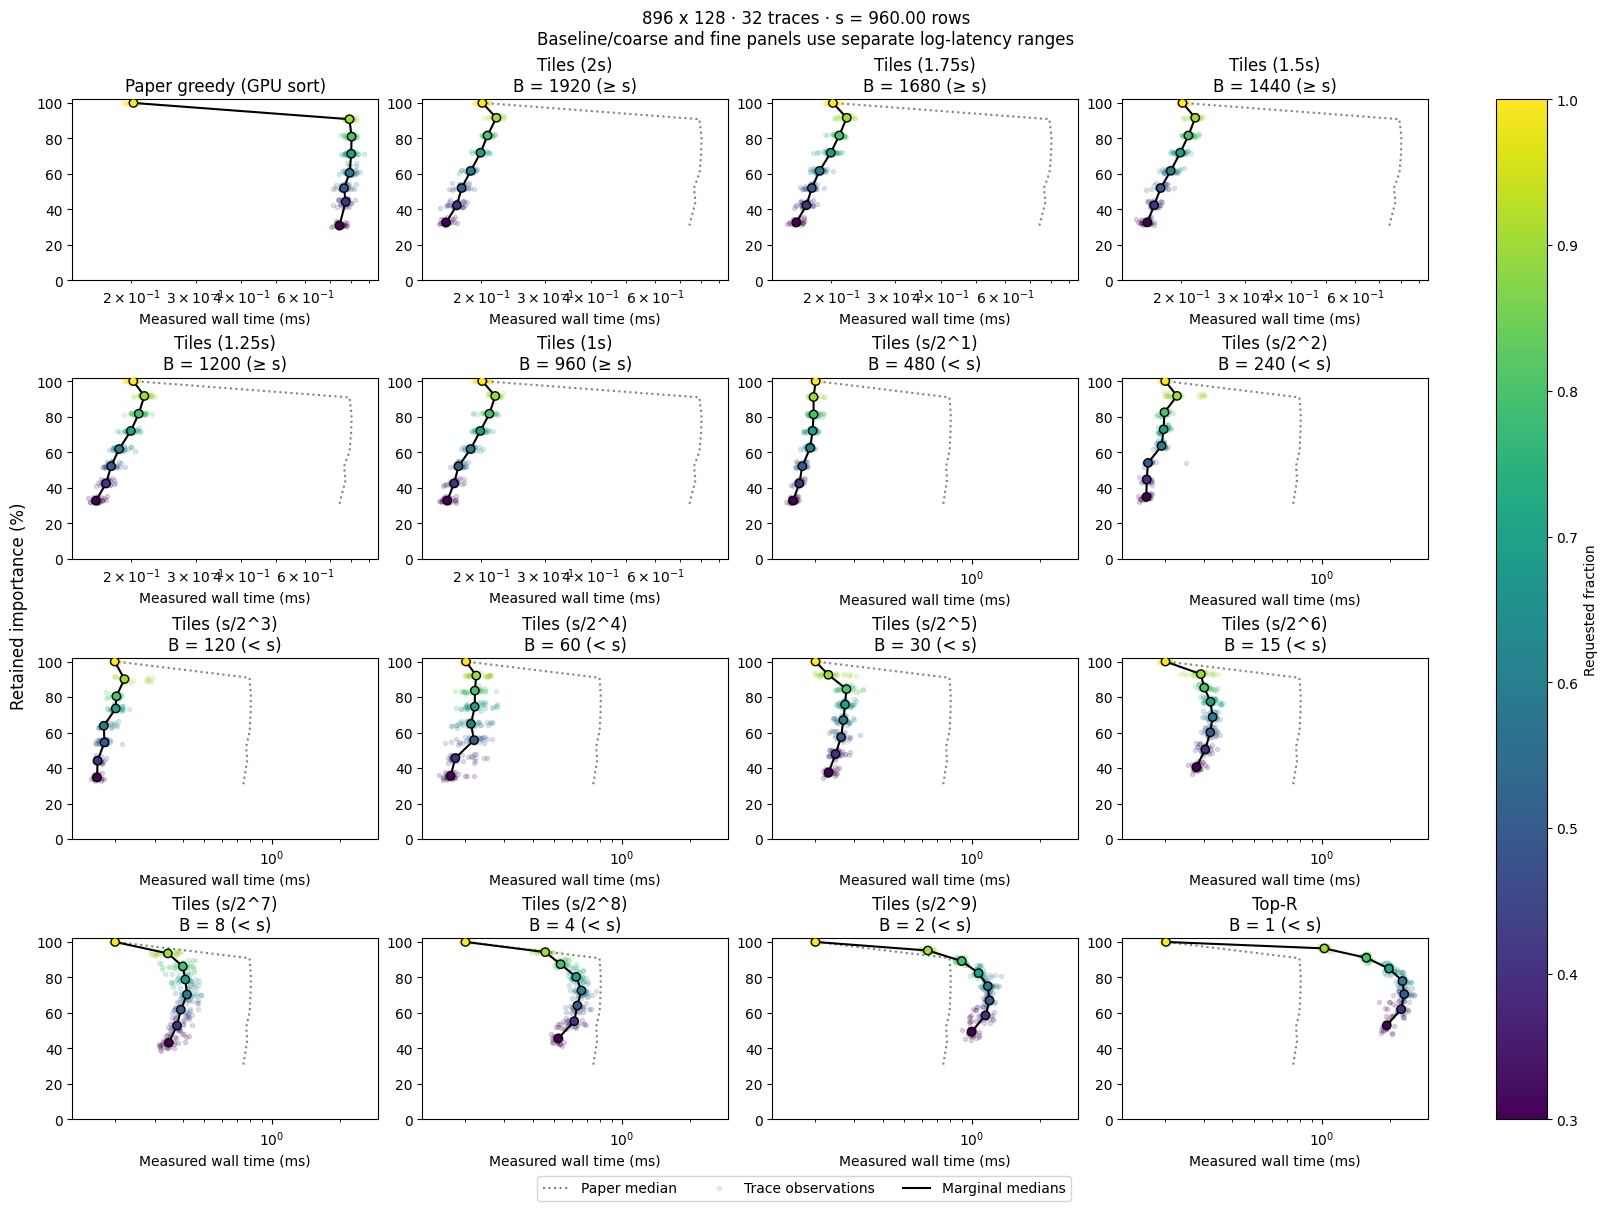

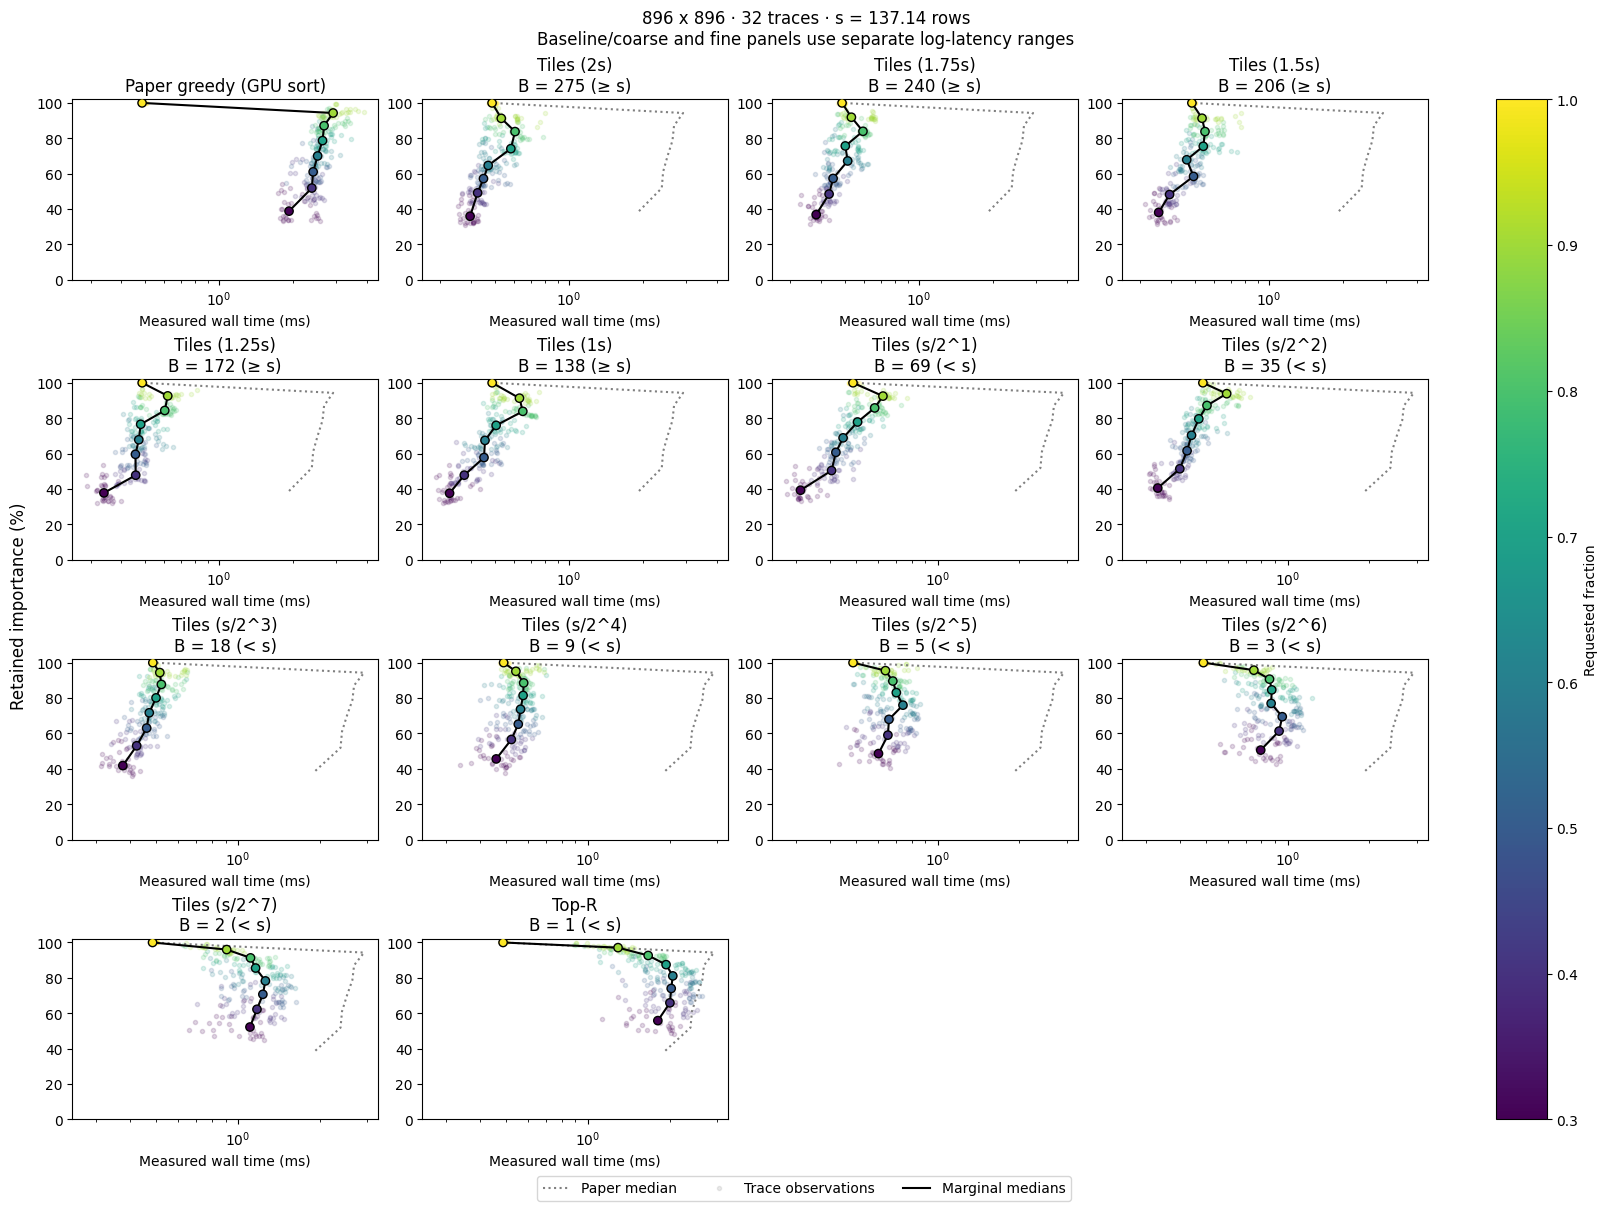

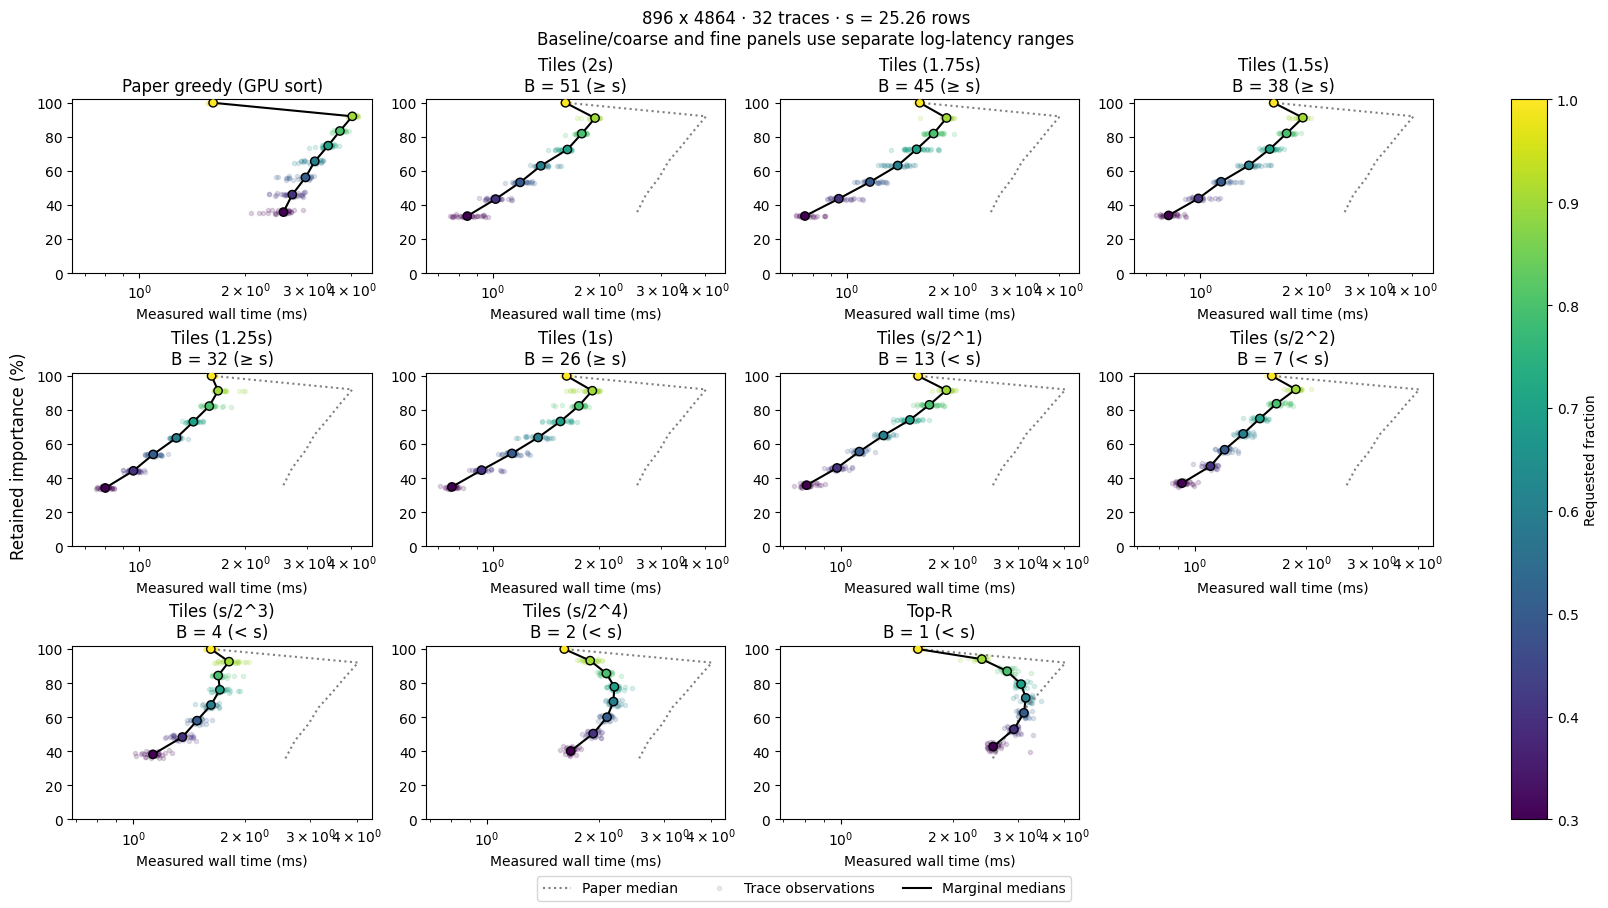

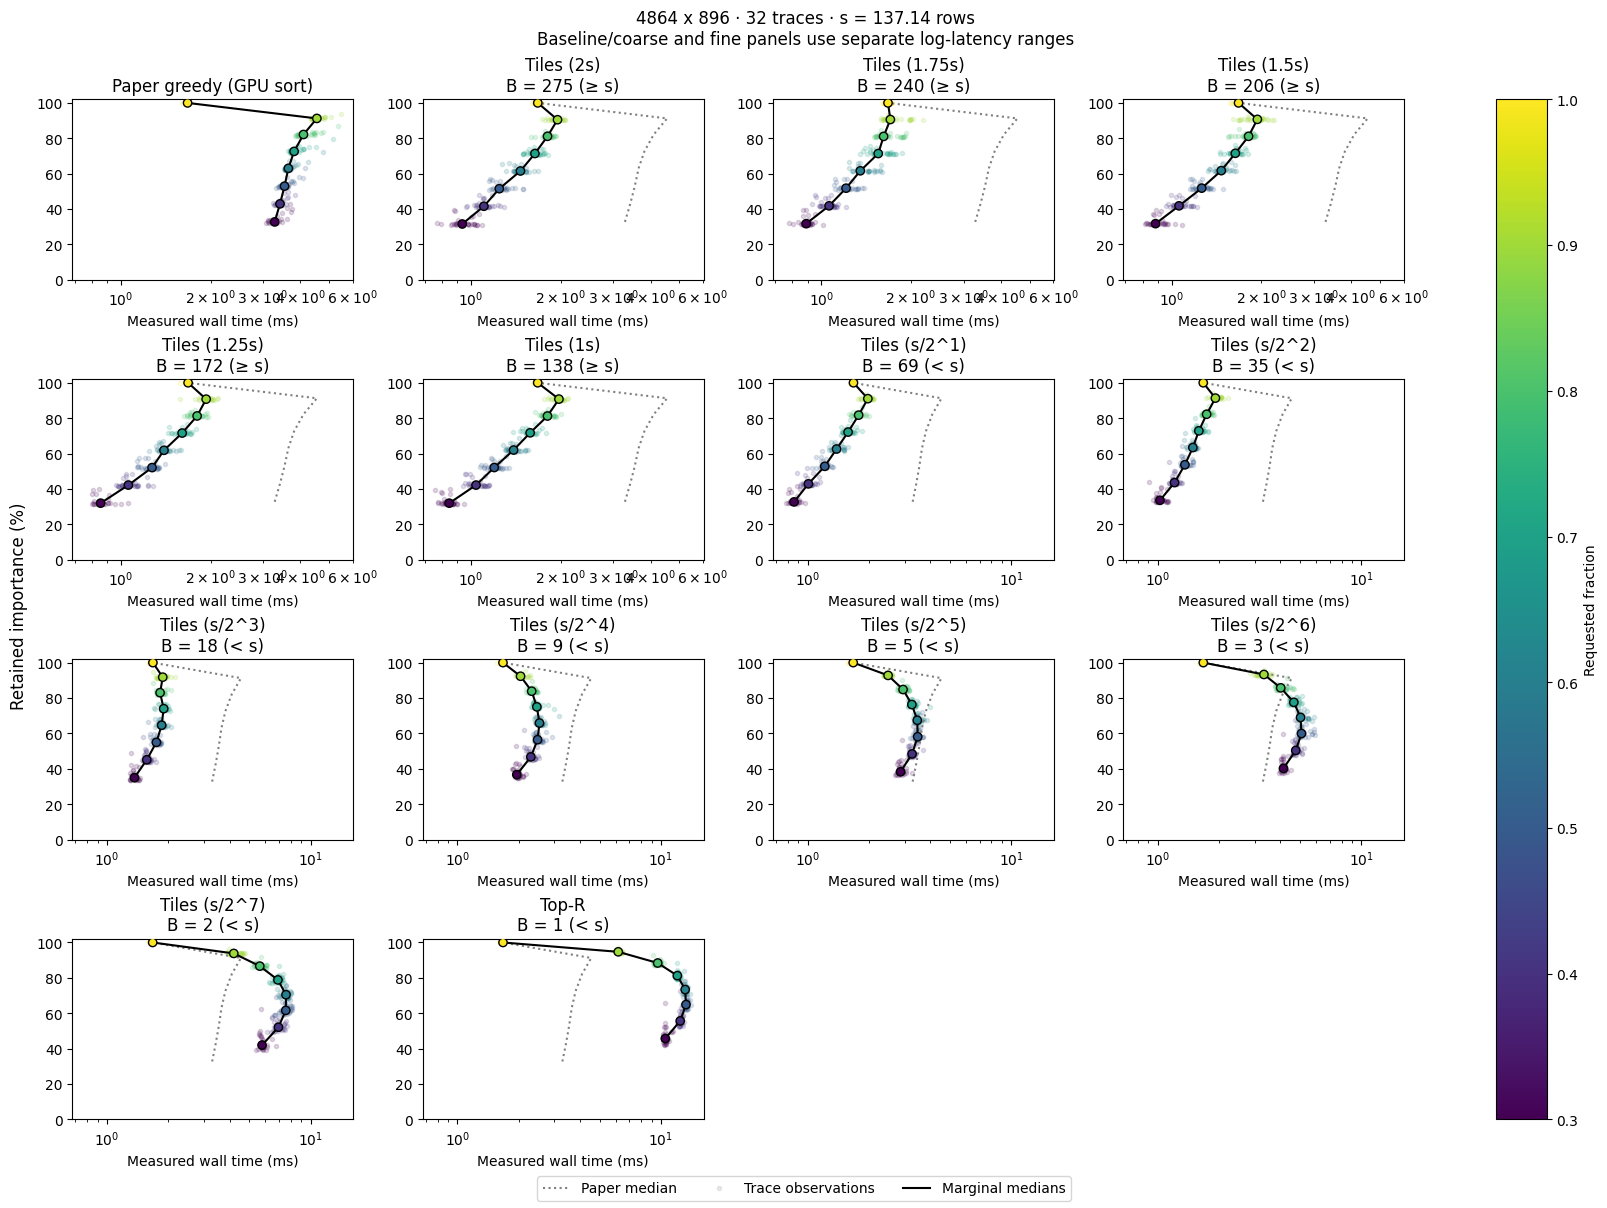

In [15]:
for result in points.values():
    fig = draw_shape(result)

    plt.show()
    plt.close(fig)

## 4. Paired differences

Compare every recorded method with Paper at the same trace and requested budget.
Report the median of these paired differences, including the full-budget control.
Negative latency changes mean faster; positive importance changes mean more retained
importance, in percentage points. Equal requested budgets may select different row counts
and retain different importance, so this is not a comparison at equal accuracy.

In [16]:
records = []

for result in points.values():
    n, d     = result.shape
    baseline = result.methods[PAPER]

    for name, method in result.methods.items():
        if name == PAPER:
            continue

        differences = method.difference_from(baseline)
        median      = differences.median()

        records.append({
            "n"                  : n,
            "d"                  : d,
            "method"             : name,
            "tile_width"         : method.tile_width,
            "delta_latency_ms"   : median.latency,
            "delta_retained_pp"  : median.retained,
        })

comparisons = pd.DataFrame(records).set_index(["n", "d", "method"])
comparisons.round(4)

tile_width  delta_latency_ms  delta_retained_pp
n    d    method                                                        
896  128  Tiles (2s)         1920.0           -0.5884             0.5648
          Tiles (1.75s)      1680.0           -0.5880             0.5648
          Tiles (1.5s)       1440.0           -0.5888             0.5648
          Tiles (1.25s)      1200.0           -0.5895             0.5648
          Tiles (1s)          960.0           -0.5892             0.5648
          Tiles (s/2^1)       480.0           -0.5944             0.1164
          Tiles (s/2^2)       240.0           -0.5875             1.2086
          Tiles (s/2^3)       120.0           -0.5882             1.2529
          Tiles (s/2^4)        60.0           -0.5669             2.4424
          Tiles (s/2^5)        30.0           -0.5191             4.1613
          Tiles (s/2^6)        15.0           -0.4702             6.1356
          Tiles (s/2^7)         8.0           -0.3880             8.0385
          Tiles (s/2^8)         4.0           -0.1749             9.8564
          Tiles (s/2^9)         2.0            0.2602            12.5084
          Top-R                 1.0            1.1921            15.2522
     896  Tiles (2s)          275.0           -2.0145            -2.3021
          Tiles (1.75s)       240.0           -2.0157            -1.5901
          Tiles (1.5s)        206.0           -2.0318            -2.1833
          Tiles (1.25s)       172.0           -2.0280            -1.8894
          Tiles (1s)          138.0           -2.0140            -1.8085
          Tiles (s/2^1)        69.0           -2.0432            -0.7576
          Tiles (s/2^2)        35.0           -2.0511             0.0009
          Tiles (s/2^3)        18.0           -2.0300             0.8848
          Tiles (s/2^4)         9.0           -1.9464             2.1077
          Tiles (s/2^5)         5.0           -1.8242             3.3003
          Tiles (s/2^6)         3.0           -1.5769             4.6494
          Tiles (s/2^7)         2.0           -1.2787             5.6221
          Top-R                 1.0           -0.5121             8.0221
     4864 Tiles (2s)           51.0           -1.7874            -1.8708
          Tiles (1.75s)        45.0           -1.7955            -1.8140
          Tiles (1.5s)         38.0           -1.8010            -1.6740
          Tiles (1.25s)        32.0           -1.8814            -1.5208
          Tiles (1s)           26.0           -1.8386            -1.1710
          Tiles (s/2^1)        13.0           -1.8409            -0.3185
          Tiles (s/2^2)         7.0           -1.7891             0.2978
          Tiles (s/2^3)         4.0           -1.5384             1.2235
          Tiles (s/2^4)         2.0           -0.9559             2.8842
          Top-R                 1.0           -0.0376             4.9054
4864 896  Tiles (2s)          275.0           -2.2912            -1.1539
          Tiles (1.75s)       240.0           -2.3468            -0.9742
          Tiles (1.5s)        206.0           -2.2884            -0.9111
          Tiles (1.25s)       172.0           -2.3245            -0.7989
          Tiles (1s)          138.0           -2.3443            -0.7759
          Tiles (s/2^1)        69.0           -2.3373            -0.2478
          Tiles (s/2^2)        35.0           -2.2390             0.3826
          Tiles (s/2^3)        18.0           -1.9087             1.3454
          Tiles (s/2^4)         9.0           -1.2543             2.5657
          Tiles (s/2^5)         5.0           -0.3413             3.7597
          Tiles (s/2^6)         3.0            0.8267             5.1126
          Tiles (s/2^7)         2.0            2.6560             6.3324
          Top-R                 1.0            7.7333             8.8594